## POLITISKY 2024 - Community Detection (NLP Tool)

Pipeline: load posts → clean text (stop/filler words) → embed → BERTopic → short topic names (1–2 words) → export → visualize.

# 1. Setup

In [3]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

# ---------------- Configuration ----------------
DATA_PATH   = Path("D:/Thesis/aria2-1.37.0-win-64bit-build1")
PARQUET     = DATA_PATH / "user_post_history_dataset.parquet"
OUTPUT_JSON = DATA_PATH / "bertopic_generated_topics.json"

SAMPLE_SIZE     = 5000   # number of posts to model (raise it as far as your RAM/time allows)
MIN_TOPIC_SIZE  = 20     # minimum posts per topic
MIN_WORDS       = 3      # drop posts with fewer meaningful words after cleaning
RANDOM_STATE    = 42
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

# 2. Load Data

The dataset is scanned lazily, so only the `Content` column of the rows we need is read into memory (the original notebook pulled all 18M posts into a Python list first).

In [4]:
posts_lf = pl.scan_parquet(PARQUET)

# Quick overview (streaming, so the full dataset is never held in memory)
overview = posts_lf.select(
    pl.len().alias("rows"),
    pl.col("Content").null_count().alias("null_content"),
    pl.col("Content").str.len_chars().mean().alias("avg_length"),
    pl.col("Content").str.len_chars().max().alias("max_length"),
).collect(engine="streaming")

print("Columns:", len(posts_lf.collect_schema().names()))
print(overview)

Columns: 16
shape: (1, 4)
┌──────────┬──────────────┬────────────┬────────────┐
│ rows     ┆ null_content ┆ avg_length ┆ max_length │
│ ---      ┆ ---          ┆ ---        ┆ ---        │
│ u32      ┆ u32          ┆ f64        ┆ u32        │
╞══════════╪══════════════╪════════════╪════════════╡
│ 18416787 ┆ 0            ┆ 124.540174 ┆ 1176       │
└──────────┴──────────────┴────────────┴────────────┘


In [5]:
raw_documents = (
    posts_lf
    .select("Content")
    .drop_nulls()
    .head(SAMPLE_SIZE)
    .collect(engine="streaming")["Content"]
    .to_list()
)

print("Posts loaded:", len(raw_documents))
print("Sample post :", raw_documents[0])

Posts loaded: 5000
Sample post : it’s a tragedy of the commons. so. anyone and everyone that ‘flies’ is a fracker. no matter how selectively they choose which science stuff to “believe” or not “believe”. if you fly you are a fracker.


# 3. Data Cleaning (Removing Stop/Filler Words)

Cleaning steps: lowercase → normalize curly quotes → remove URLs, @mentions, HTML entities, numbers, emojis/punctuation → split contractions (`don't`, `it's`) → drop stop words, filler words, and single-letter tokens.

Two versions of each post are kept:
- **embedding text**: lightly cleaned (URLs/mentions removed) because sentence-transformers needs real sentences to understand meaning.
- **topic text**: fully cleaned (stop/filler words removed) and used to extract topic keywords.

In [6]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Words that carry no topical meaning in social-media posts
FILLER_WORDS = {
    # conversational filler / fillers of speech
    "like", "just", "really", "actually", "literally", "basically", "honestly", "seriously",
    "totally", "simply", "probably", "maybe", "pretty", "quite", "kinda", "sorta", "ever",
    "yeah", "yes", "yep", "nope", "okay", "ok", "oh", "ah", "um", "uh", "hmm", "well",
    "lol", "lmao", "lmfao", "haha", "hahaha", "omg", "wow", "hey", "hi", "hello", "bye",
    "thanks", "thank", "thankyou", "thx", "ty", "please", "pls", "sorry", "welcome",
    # generic verbs / nouns
    "know", "think", "thought", "going", "gonna", "gotta", "wanna", "said", "say", "says",
    "saying", "got", "get", "gets", "getting", "let", "lets", "make", "makes", "made",
    "making", "come", "comes", "came", "go", "goes", "went", "want", "wants", "need",
    "needs", "look", "looks", "looking", "see", "seen", "take", "takes", "taken", "put",
    "give", "gave", "tell", "told", "try", "trying", "use", "used", "keep", "mean", "means",
    "thing", "things", "stuff", "way", "ways", "lot", "lots", "bit", "kind", "sort",
    "guy", "guys", "man", "dude", "people", "someone", "anyone", "everyone", "everybody",
    "nobody", "anybody", "something", "anything", "everything", "nothing",
    # generic adjectives / adverbs / time
    "good", "great", "best", "better", "bad", "worse", "new", "old", "right", "wrong",
    "sure", "true", "real", "big", "little", "long", "high", "low", "first", "last",
    "next", "many", "much", "even", "still", "also", "already", "always", "never",
    "today", "tonight", "tomorrow", "yesterday", "day", "days", "time", "times", "year",
    "years", "week", "now", "ago", "soon", "later", "again", "away", "back", "though",
    "yet", "ones", "one", "two", "three",
    # contraction fragments / negations
    "don", "doesn", "didn", "isn", "aren", "wasn", "weren", "won", "wouldn", "couldn",
    "shouldn", "haven", "hasn", "hadn", "ain", "dont", "doesnt", "didnt", "isnt", "arent",
    "wasnt", "werent", "wont", "wouldnt", "couldnt", "shouldnt", "cant", "cannot", "havent",
    "hasnt", "hadnt", "im", "ive", "ill", "id", "youre", "youve", "youll", "hes", "shes",
    "thats", "theres", "heres", "whats", "lets", "theyre", "theyve", "theyll", "weve",
    "ll", "ve", "re", "isn", "amp",
    # dataset artifacts
    "anonymous", "http", "https", "www", "com", "rt", "via", "user", "users", "post", "posts",
}

STOP_WORDS = frozenset(ENGLISH_STOP_WORDS) | FILLER_WORDS

URL_RE      = re.compile(r"(?:https?|ftp)\S*|www\.\S+|\S+\.(?:com|org|net|gov)\b\S*", re.I)
MENTION_RE  = re.compile(r"@\w+")
ENTITY_RE   = re.compile(r"&\w+;")
TOKEN_RE    = re.compile(r"[a-z]+(?:'[a-z]+)*")
SUFFIX_RE   = re.compile(r"'(?:s|re|ve|ll|d|m)$")

def light_clean(text: str) -> str:
    """Remove noise but keep the sentence intact (used for embeddings)."""
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = ENTITY_RE.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()

def clean_text(text: str) -> str:
    """Full cleaning: keep only meaningful lowercase words (used for topic keywords)."""
    text = light_clean(text).lower().replace("#", " ")
    words = []
    for token in TOKEN_RE.findall(text):
        if token.endswith("n't"):                 # don't, can't, isn't ... -> negation filler
            continue
        token = SUFFIX_RE.sub("", token)          # it's -> it, they're -> they
        token = token.replace("'", "")
        if len(token) < 2 or token in STOP_WORDS:
            continue
        words.append(token)
    return " ".join(words)

In [7]:
# Sanity check on a few posts
for post in raw_documents[:3]:
    print("RAW  :", post)
    print("CLEAN:", clean_text(post), "\n")

RAW  : it’s a tragedy of the commons. so. anyone and everyone that ‘flies’ is a fracker. no matter how selectively they choose which science stuff to “believe” or not “believe”. if you fly you are a fracker.
CLEAN: tragedy commons flies fracker matter selectively choose science believe believe fly fracker 

RAW  : Notícia da @anonymous

"Xi Jinping arrives in Brasília for meeting with Lula, welcomed by a percussion group and chinese supporters at the hotel"

Link sem paywall ⬇️

CLEAN: cia da xi jinping arrives bras lia meeting lula welcomed percussion group chinese supporters hotel link sem paywall 

RAW  : Have you run it by the Godless Democratic Party.

You'll be crucified on the first day of a Dem President in 2029.

Then again, you did that to your son.  Maybe you deserve it as well.

See you at the resurrection!
CLEAN: run godless democratic party crucified dem president did son deserve resurrection 



In [8]:
# Apply cleaning and drop posts that have (almost) nothing left
embedding_texts, cleaned_documents, original_documents = [], [], []

for post in raw_documents:
    cleaned = clean_text(post)
    if len(cleaned.split()) >= MIN_WORDS:
        embedding_texts.append(light_clean(post))
        cleaned_documents.append(cleaned)
        original_documents.append(post)

print(f"Kept {len(cleaned_documents):,} of {len(raw_documents):,} posts "
      f"({len(raw_documents) - len(cleaned_documents):,} dropped as too short after cleaning)")

Kept 3,513 of 5,000 posts (1,487 dropped as too short after cleaning)


# 4. Embeddings

In [9]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(EMBEDDING_MODEL)

embeddings = embedding_model.encode(
    embedding_texts,
    batch_size=64,
    show_progress_bar=True,
)
print("Embedding shape:", embeddings.shape)

c:\Users\geryl\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|██████████| 55/55 [01:09<00:00,  1.26s/it]

Embedding shape: (3513, 384)


# 5. Topic Modeling (BERTopic)

Stop words are filtered again inside the `CountVectorizer`, so topic keywords can never contain stop/filler words. Only single words are used so that topic names stay short.

In [10]:
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP
from hdbscan import HDBSCAN

vectorizer_model = CountVectorizer(
    stop_words=list(STOP_WORDS),
    token_pattern=r"(?u)\b[a-z]{2,}\b",
    ngram_range=(1, 1),
    min_df=2,
)

umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                  metric="cosine", random_state=RANDOM_STATE)

hdbscan_model = HDBSCAN(min_cluster_size=MIN_TOPIC_SIZE, metric="euclidean",
                        cluster_selection_method="eom", prediction_data=True)

topic_model = BERTopic(
    embedding_model=None,            # embeddings are passed in manually
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    verbose=True,
)

topics, probabilities = topic_model.fit_transform(cleaned_documents, embeddings)

2026-10-31 15:17:35,610 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-31 15:18:09,005 - BERTopic - Dimensionality - Completed ✓
2026-10-31 15:18:09,007 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-31 15:18:09,169 - BERTopic - Cluster - Completed ✓
2026-10-31 15:18:09,187 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-31 15:18:09,280 - BERTopic - Representation - Completed ✓


# 6. Short Topic Names (1–2 Words)

Each topic is named after its two strongest keywords (single keyword if only one is available). Near-duplicates such as *russia / russian* are skipped, and names are kept unique across topics.

In [11]:
def build_topic_names(model, max_words=2, pool=10):
    names, used = {}, set()

    def too_similar(a, b):
        return a[:5] == b[:5]

    for topic_id in sorted(model.get_topics()):
        if topic_id == -1:
            names[-1] = "Outliers"
            continue

        candidates = []
        for word, _ in model.get_topic(topic_id)[:pool]:
            if word not in STOP_WORDS and not any(too_similar(word, c) for c in candidates):
                candidates.append(word)

        # Try (1st, 2nd), (1st, 3rd), ... until the name is unique; fall back to 1 word
        options = [candidates[:1] + [c] for c in candidates[1:]] if max_words > 1 else []
        options.append(candidates[:1])
        label = next((" ".join(o).title() for o in options if " ".join(o).title() not in used),
                     f"{candidates[0].title()} {topic_id}")

        used.add(label)
        names[topic_id] = label
    return names

topic_names = build_topic_names(topic_model)
topic_model.set_topic_labels(topic_names)

topic_info = topic_model.get_topic_info()[["Topic", "Count", "CustomName", "Representation"]]
topic_info = topic_info.rename(columns={"CustomName": "TopicName", "Representation": "Keywords"})
topic_info

,Topic,Count,TopicName,Keywords
0,-1,1476,Outliers,"[trump, believe, state, states, coming, blue, ..."
1,0,264,Block Threads,"[block, blocked, threads, twitter, list, accou..."
2,1,144,Democrats Vote,"[democrats, vote, votes, harris, election, dem..."
3,2,137,Medicare Oz,"[medicare, oz, dr, medicaid, doctor, tv, healt..."
4,3,113,Ukraine Russia,"[ukraine, russia, putin, russian, nuclear, mos..."
5,4,98,Education Secretary,"[education, secretary, department, expected, n..."
6,5,89,Da La,"[da, la, cia, en, link, di, em, et, die, il]"
7,6,75,Trump Picks,"[trump, picks, agenda, cabinet, term, federal,..."
8,7,55,Mace Nancy,"[mace, nancy, sarah, mcbride, rape, survivor, ..."
9,8,51,News Number,"[news, number, media, fearless, outlets, repor..."


# 7. Export Topics to JSON

In [12]:
doc_df = pd.DataFrame({
    "topic": topics,
    "prob": np.asarray(probabilities).reshape(len(topics), -1).max(axis=1),
    "post": original_documents,
})

all_topics = []
for _, row in topic_info.iterrows():
    topic_id = int(row["Topic"])
    keywords = topic_model.get_topic(topic_id) or []

    # Most representative ORIGINAL (uncleaned) posts for this topic
    top_posts = (
        doc_df[doc_df["topic"] == topic_id]
        .nlargest(5, "prob")["post"]
        .tolist()
    )

    all_topics.append({
        "topic_id": topic_id,
        "topic_title": row["TopicName"],
        "post_count": int(row["Count"]),
        "keywords": [{"word": w, "score": float(s)} for w, s in keywords],
        "representative_posts": top_posts,
    })

with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
    json.dump(all_topics, f, ensure_ascii=False, indent=4)

print(f"Saved {len(all_topics)} topics to: {OUTPUT_JSON}")

Saved 42 topics to: D:\Thesis\aria2-1.37.0-win-64bit-build1\bertopic_generated_topics.json


# 8. Visualization

### 8.1 Topic sizes

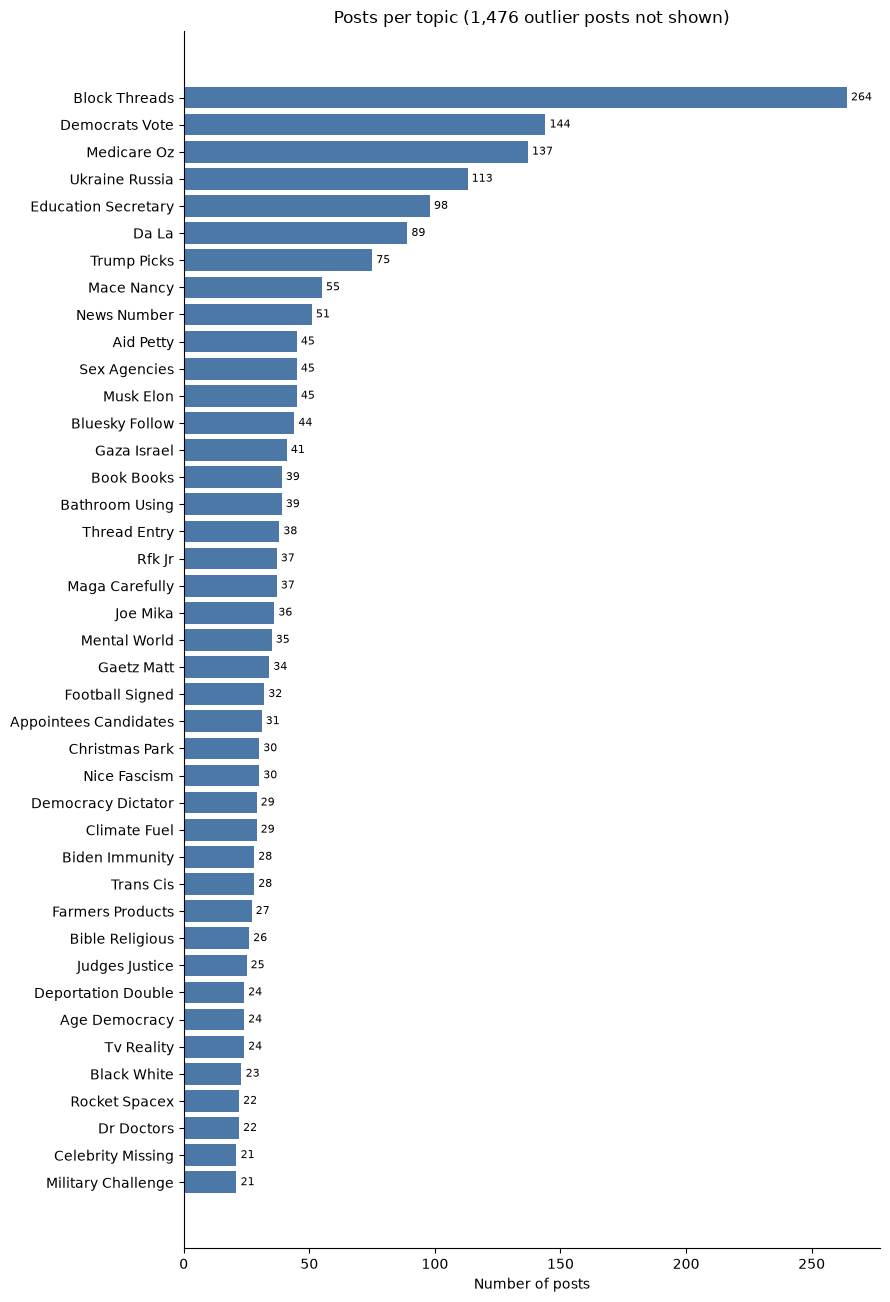

In [13]:
sizes = topic_info[topic_info["Topic"] != -1].sort_values("Count")
n_outliers = int(topic_info.loc[topic_info["Topic"] == -1, "Count"].sum())

fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(sizes))))
bars = ax.barh(sizes["TopicName"], sizes["Count"], color="#4C78A8")
ax.bar_label(bars, padding=3, fontsize=8)
ax.set_xlabel("Number of posts")
ax.set_title(f"Posts per topic ({n_outliers:,} outlier posts not shown)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 8.2 Top keywords per topic

In [14]:
topic_model.visualize_barchart(top_n_topics=12, n_words=6, custom_labels=True)

### 8.3 Topic similarity map (intertopic distance)

In [15]:
topic_model.visualize_topics(custom_labels=True)

### 8.4 Posts map

Every dot is one post, coloured by topic (hover to read the post). Use the legend to show or hide topics.

In [16]:
from umap import UMAP

reduced_embeddings = UMAP(n_neighbors=15, n_components=2, min_dist=0.0,
                          metric="cosine", random_state=RANDOM_STATE).fit_transform(embeddings)

topic_model.visualize_documents(
    original_documents,
    reduced_embeddings=reduced_embeddings,
    custom_labels=True,
    hide_annotations=True,
)

### 8.5 Topic hierarchy

In [17]:
topic_model.visualize_hierarchy(custom_labels=True)